In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sys.path.append(str(Path.cwd().parent))
from src.config import get_local_db

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 150

db = get_local_db()
col = db["pageviews"]

# Pobieramy dane dla PL i EN ze wszystkich 3 dni (13, 14, 15 lutego)
cursor = col.find(
    {"date": {"$in": ["2026-02-13", "2026-02-14", "2026-02-15"]}},
    {"_id": 0, "project": 1, "article": 1, "date": 1, "daily_total": 1, "access": 1}
)
df_all = pd.DataFrame(list(cursor))

print(f"Pobrano łącznie {len(df_all):,} rekordów z bazy.")

Pobrano łącznie 1,778,352 rekordów z bazy.


,Projekt,Liczba rekordów,Suma wyświetleń,Średnia,Mediana (Q50),IQR (Q75-Q25),95. percentyl,99. percentyl,Maksimum
0,en.wikipedia,1727071,467254628,270.5,105.0,139.0,817.0,2595.0,497423
1,pl.wikipedia,51281,9876401,192.6,86.0,82.0,439.0,1502.2,201293


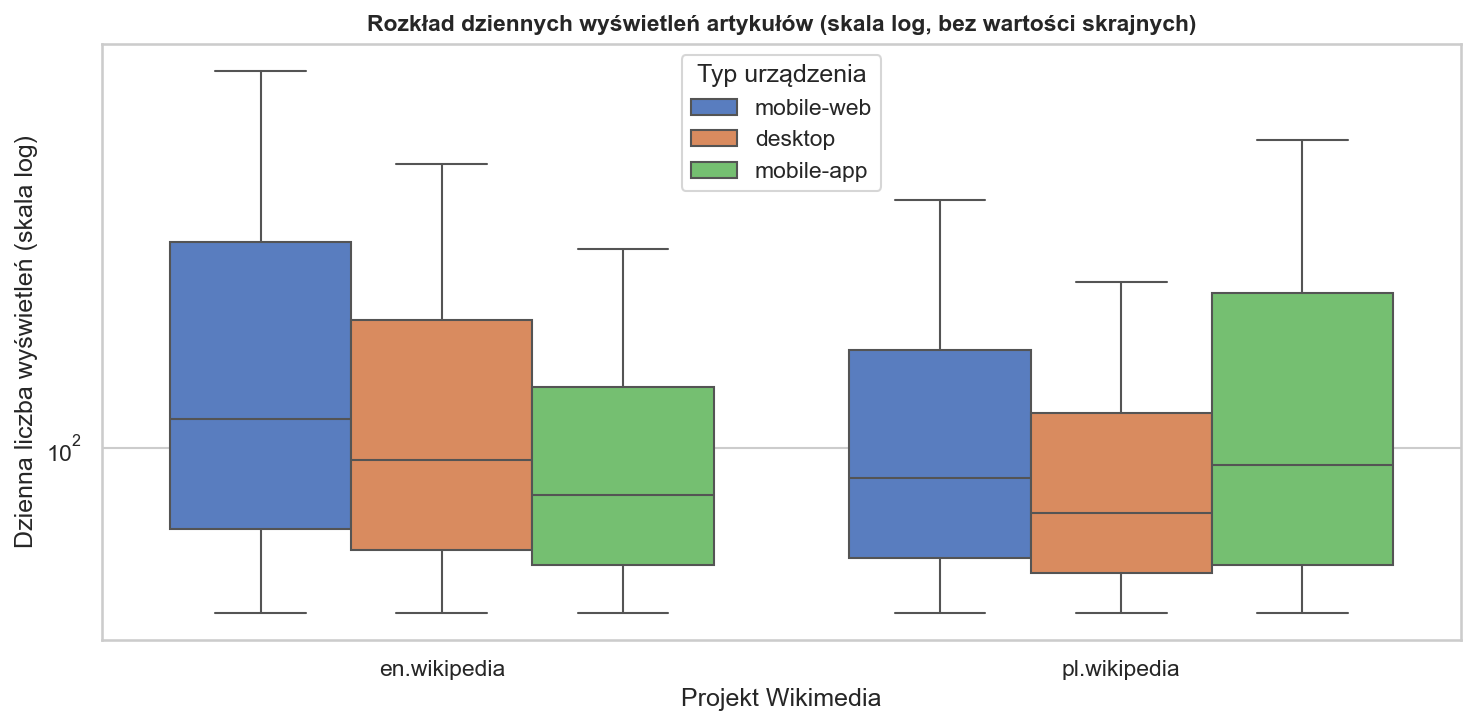

In [3]:
cursor = col.find(
    {},
    {"_id": 0, "project": 1, "access": 1, "daily_total": 1}
)
df = pd.DataFrame(list(cursor))

stats_rows = []
for project, group in df.groupby("project"):
    vals = group["daily_total"]
    q25, q50, q75 = np.percentile(vals, [25, 50, 75])
    p95, p99 = np.percentile(vals, [95, 99])
    stats_rows.append({
        "Projekt": project,
        "Liczba rekordów": len(vals),
        "Suma wyświetleń": vals.sum(),
        "Średnia": round(vals.mean(), 1),
        "Mediana (Q50)": round(q50, 1),
        "IQR (Q75-Q25)": round(q75 - q25, 1),
        "95. percentyl": round(p95, 1),
        "99. percentyl": round(p99, 1),
        "Maksimum": vals.max(),
    })

stats_df = pd.DataFrame(stats_rows)
display(stats_df)
stats_df.to_csv(OUTPUT_DIR / "1_descriptive_stats.csv", index=False)

# Wykres pudełkowy w skali logarytmicznej
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x="project",
    y="daily_total",
    hue="access",
    showfliers=False,
)
plt.yscale("log")
plt.title("Rozkład dziennych wyświetleń artykułów (skala log, bez wartości skrajnych)", fontsize=11, fontweight="bold")
plt.xlabel("Projekt Wikimedia")
plt.ylabel("Dzienna liczba wyświetleń (skala log)")
plt.legend(title="Typ urządzenia")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "1_distribution_box_log.png")
plt.show()

access,desktop,mobile-app,mobile-web
project,,,
en.wikipedia,24.41,1.42,74.18
pl.wikipedia,12.43,0.24,87.32


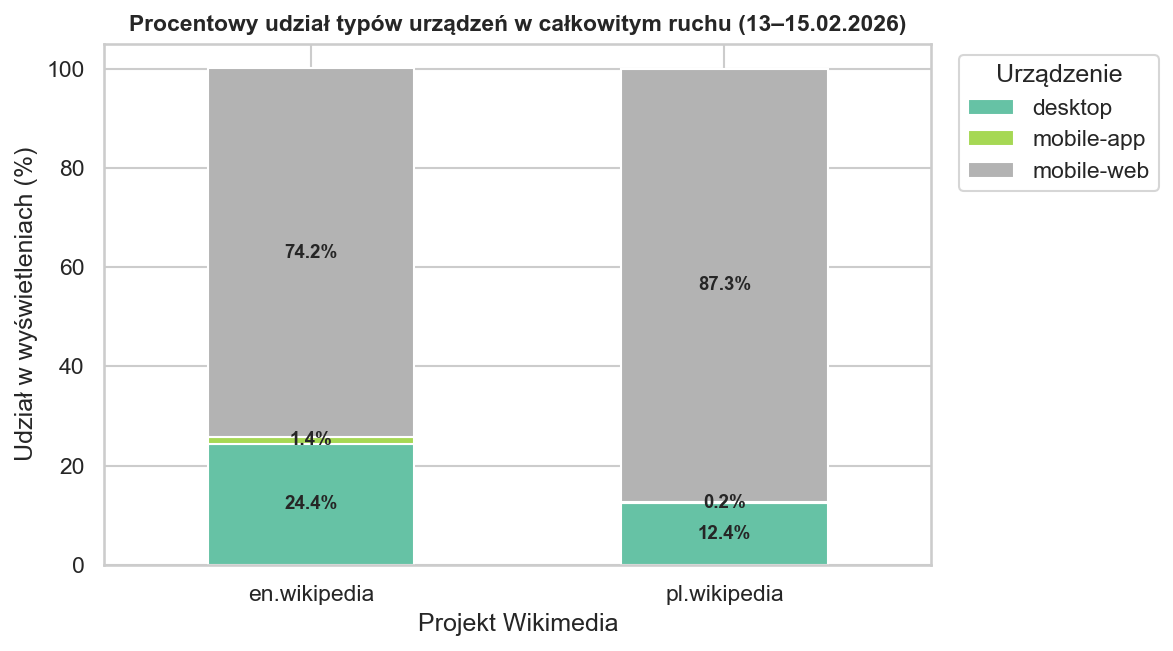

In [5]:
pipeline = [
    {
        "$group": {
            "_id": {"project": "$project", "access": "$access"},
            "total_views": {"$sum": "$daily_total"},
            "records_count": {"$sum": 1},
        }
    }
]
raw = list(col.aggregate(pipeline))
rows = [
    {
        "project": r["_id"]["project"],
        "access": r["_id"]["access"],
        "total_views": r["total_views"],
        "records_count": r["records_count"],
    }
    for r in raw
]
df_device = pd.DataFrame(rows)
df_device["share_pct"] = df_device.groupby("project")["total_views"].transform(lambda x: 100 * x / x.sum())

pivot_df = df_device.pivot(index="project", columns="access", values="share_pct").round(2)
display(pivot_df)
df_device.to_csv(OUTPUT_DIR / "2_device_share.csv", index=False)

ax = pivot_df.plot(kind="bar", stacked=True, figsize=(8, 4.5), colormap="Set2")
plt.title("Procentowy udział typów urządzeń w całkowitym ruchu (13–15.02.2026)", fontsize=11, fontweight="bold")
plt.xlabel("Projekt Wikimedia")
plt.ylabel("Udział w wyświetleniach (%)")
plt.xticks(rotation=0)
plt.legend(title="Urządzenie", bbox_to_anchor=(1.02, 1), loc="upper left")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "2_device_share.png")
plt.show()

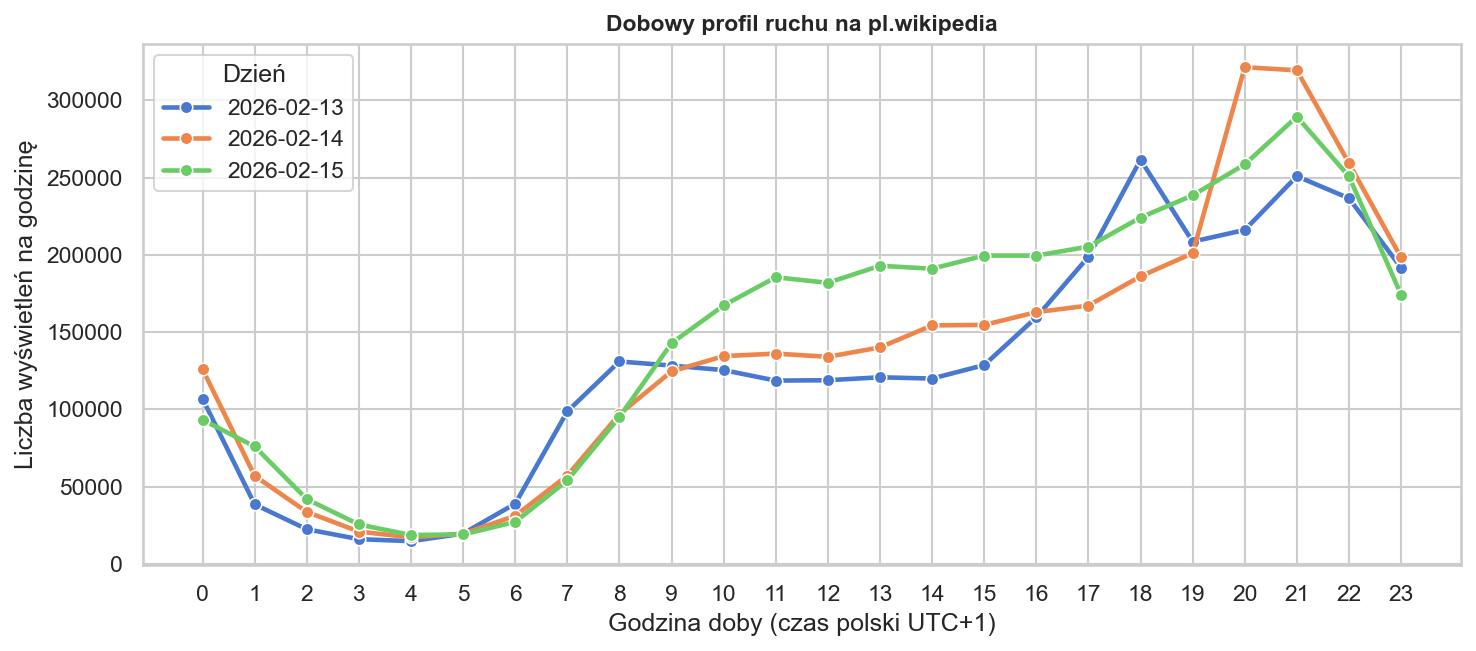

In [7]:
hour_fields = {f"h_{h}": {"$sum": f"$hourly_counts.{h}"} for h in range(24)}
pipeline = [
    {"$match": {"project": "pl.wikipedia"}},
    {"$group": {"_id": "$date", **hour_fields}},
    {"$sort": {"_id": 1}},
]
results = list(col.aggregate(pipeline))

plot_rows = []
for doc in results:
    date_label = doc["_id"]
    total_day = sum(doc[f"h_{h}"] for h in range(24))
    for h in range(24):
        # Przeliczenie UTC na czas lokalny w Polsce (UTC+1)
        local_hour = (h + 1) % 24
        views = doc[f"h_{h}"]
        plot_rows.append({
            "Data": date_label,
            "Godzina_PL": local_hour,
            "Wyświetlenia": views,
            "Udział_dobowy_pct": round(100 * views / total_day, 2) if total_day else 0,
        })

df_hourly = pd.DataFrame(plot_rows).sort_values(["Data", "Godzina_PL"])
df_hourly.to_csv(OUTPUT_DIR / "3_hourly_profile.csv", index=False)

plt.figure(figsize=(10, 4.5))
sns.lineplot(
    data=df_hourly,
    x="Godzina_PL",
    y="Wyświetlenia",
    hue="Data",
    marker="o",
    linewidth=2.2,
)
plt.title("Dobowy profil ruchu na pl.wikipedia", fontsize=11, fontweight="bold")
plt.xlabel("Godzina doby (czas polski UTC+1)")
plt.ylabel("Liczba wyświetleń na godzinę")
plt.xticks(range(0, 24))
plt.legend(title="Dzień")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "3_hourly_profile.png")
plt.show()

,tytuł,views_13,views_14,views_15,total_3days
0,Władimir Siemirunnij,233189,50565,12823,296577
1,Bożena Dykiel,231516,31500,12416,275432
2,Jolanta Wadowska-Król,67549,79859,107219,254627
3,Ołowiane dzieci,28643,30667,67192,126502
4,Huta Metali Nieżelaznych Szopienice,31372,40265,52987,124624
5,Kacper Tomasiak,3912,64355,38198,106465
6,Jeffrey Epstein,24556,20022,20419,64997
7,Ilia Malinin,22552,24972,8389,55913


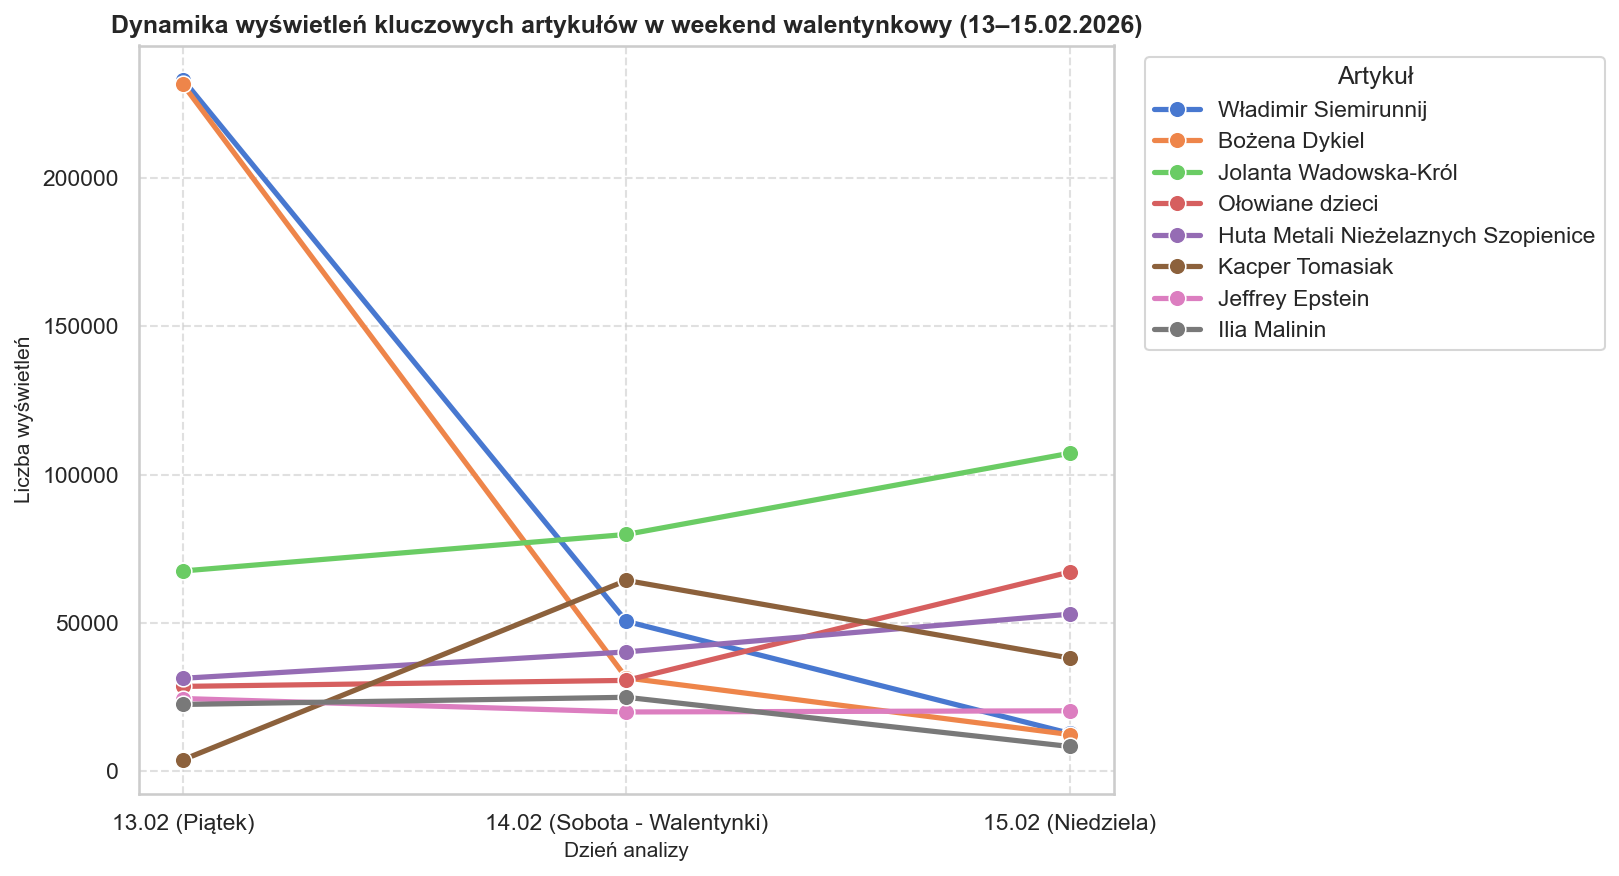

In [9]:
# Analiza dynamiki TOP artykułów w całym oknie 3 dni (13.02 – 15.02)
pipeline_3days = [
    {"$match": {"project": "pl.wikipedia", "date": {"$in": ["2026-02-13", "2026-02-14", "2026-02-15"]}}},
    {
        "$group": {
            "_id": {"article": "$article", "date": "$date"},
            "views": {"$sum": "$daily_total"},
        }
    },
    {
        "$group": {
            "_id": "$_id.article",
            "views_13": {
                "$sum": {"$cond": [{"$eq": ["$_id.date", "2026-02-13"]}, "$views", 0]}
            },
            "views_14": {
                "$sum": {"$cond": [{"$eq": ["$_id.date", "2026-02-14"]}, "$views", 0]}
            },
            "views_15": {
                "$sum": {"$cond": [{"$eq": ["$_id.date", "2026-02-15"]}, "$views", 0]}
            },
            "total_3days": {"$sum": "$views"}
        }
    },
    # Wybieramy artykuły, które miały znaczący ruch w tym okresie
    {"$match": {"views_14": {"$gte": 4000}}},
    {"$sort": {"total_3days": -1}},
    {"$limit": 8}, # TOP 8 artykułów, żeby wykres był czytelny
]

results_3days = list(col.aggregate(pipeline_3days))
df_wide = pd.DataFrame(results_3days)
df_wide["tytuł"] = df_wide["_id"].str.replace("_", " ")

# Przekształcamy tabelę z formatu szerokiego na długi (tzw. melt) dla biblioteki Seaborn
df_long = df_wide.melt(
    id_vars=["tytuł"],
    value_vars=["views_13", "views_14", "views_15"],
    var_name="Dzień_Kod",
    value_name="Wyświetlenia"
)

# Ładne etykiety dni na osi X
day_mapping = {
    "views_13": "13.02 (Piątek)",
    "views_14": "14.02 (Sobota - Walentynki)",
    "views_15": "15.02 (Niedziela)"
}
df_long["Dzień"] = df_long["Dzień_Kod"].map(day_mapping)

# Wyświetlamy tabelę podsumowującą w notebooku
display(df_wide[["tytuł", "views_13", "views_14", "views_15", "total_3days"]])
df_wide.to_csv(OUTPUT_DIR / "3days_dynamics.csv", index=False)

# Wykres dynamiki (trajektorie trendu)
plt.figure(figsize=(11, 6))
sns.lineplot(
    data=df_long,
    x="Dzień",
    y="Wyświetlenia",
    hue="tytuł",
    marker="o",
    linewidth=2.5,
    markersize=8
)

plt.title("Dynamika wyświetleń kluczowych artykułów w weekend walentynkowy (13–15.02.2026)", fontsize=12, fontweight="bold")
plt.xlabel("Dzień analizy", fontsize=10)
plt.ylabel("Liczba wyświetleń", fontsize=10)
plt.legend(title="Artykuł", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "6_3days_dynamics_trend.png")
plt.show()

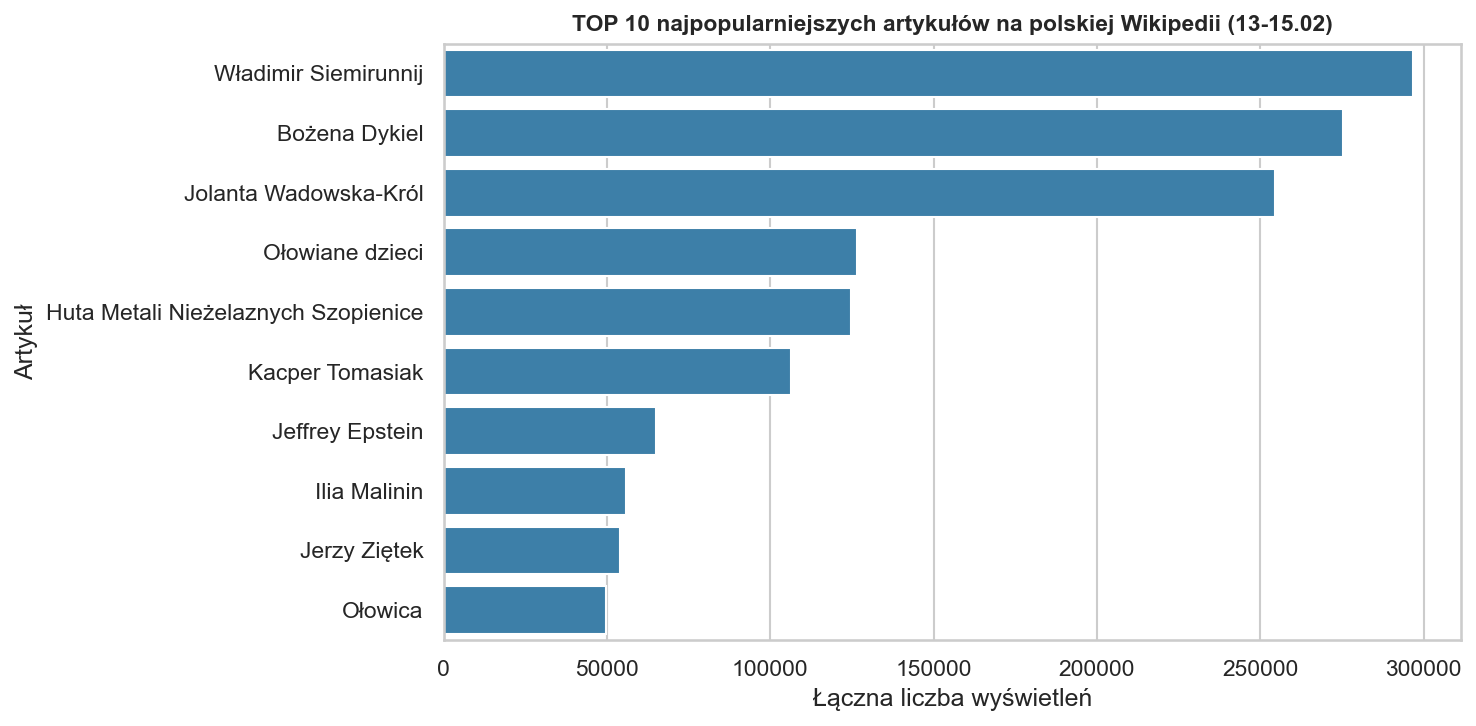

In [12]:
df_pl = df_all[df_all["project"] == "pl.wikipedia"]
top_pl = df_pl.groupby("article")["daily_total"].sum().reset_index()
top_pl = top_pl.sort_values(by="daily_total", ascending=False).head(10)
top_pl["tytuł"] = top_pl["article"].str.replace("_", " ")

plt.figure(figsize=(10, 5))
sns.barplot(data=top_pl, x="daily_total", y="tytuł", color="#2b83ba")
plt.title("TOP 10 najpopularniejszych artykułów na polskiej Wikipedii (13-15.02)", fontsize=11, fontweight="bold")
plt.xlabel("Łączna liczba wyświetleń")
plt.ylabel("Artykuł")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "chart_1_pl_top.png")
plt.show()

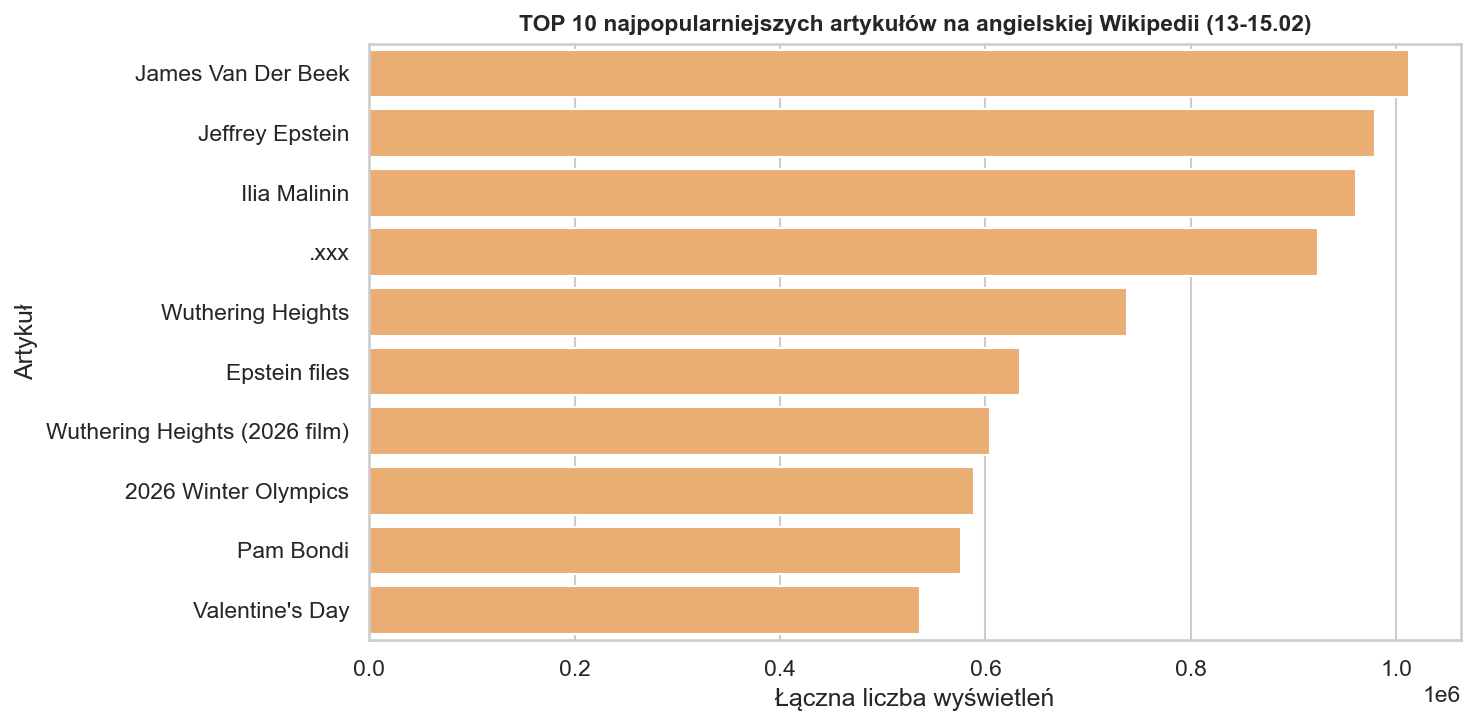

In [14]:
df_en = df_all[df_all["project"] == "en.wikipedia"]
top_en = df_en.groupby("article")["daily_total"].sum().reset_index()
top_en = top_en.sort_values(by="daily_total", ascending=False).head(10)
top_en["tytuł"] = top_en["article"].str.replace("_", " ")

plt.figure(figsize=(10, 5))
sns.barplot(data=top_en, x="daily_total", y="tytuł", color="#fdae61")
plt.title("TOP 10 najpopularniejszych artykułów na angielskiej Wikipedii (13-15.02)", fontsize=11, fontweight="bold")
plt.xlabel("Łączna liczba wyświetleń")
plt.ylabel("Artykuł")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "chart_2_en_top.png")
plt.show()

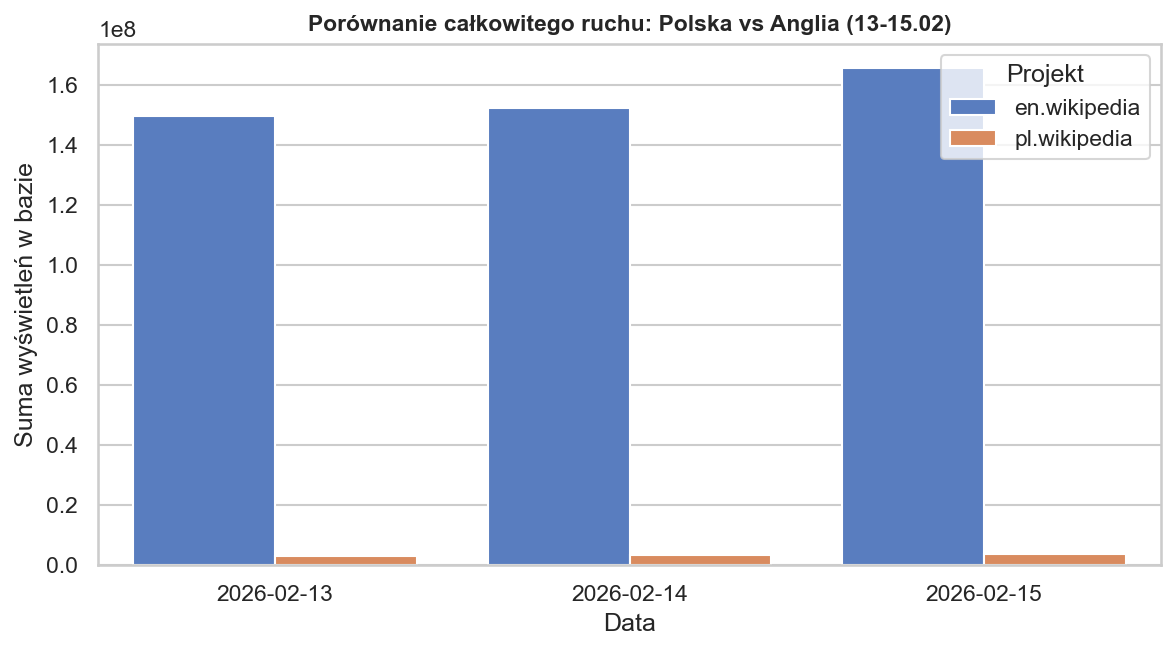

In [15]:
scale_df = df_all.groupby(["project", "date"], as_index=False)["daily_total"].sum()

plt.figure(figsize=(8, 4.5))
sns.barplot(data=scale_df, x="date", y="daily_total", hue="project")
plt.title("Porównanie całkowitego ruchu: Polska vs Anglia (13-15.02)", fontsize=11, fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Suma wyświetleń w bazie")
plt.legend(title="Projekt")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "chart_3_scale_comparison.png")
plt.show()

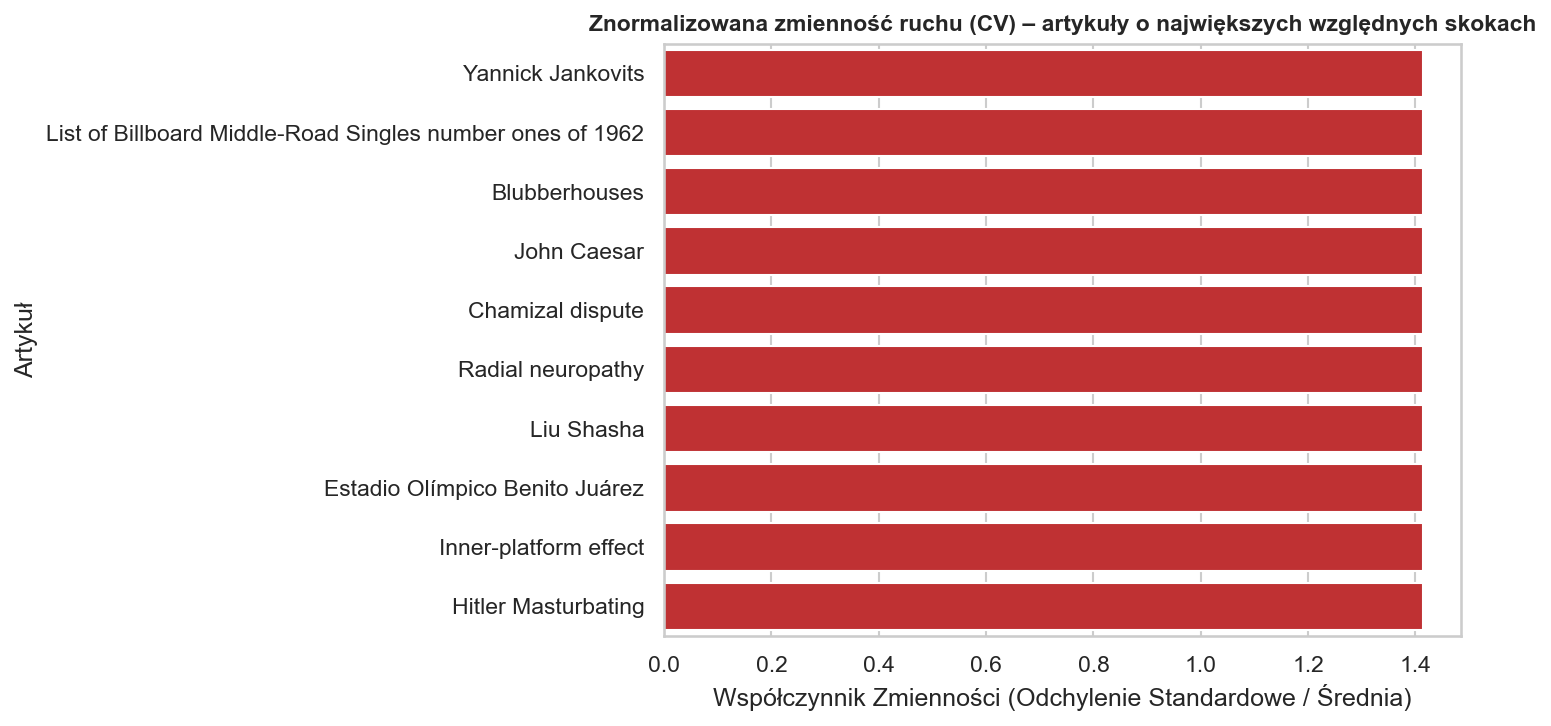

In [24]:
pivot_days = df_en.pivot_table(index="article", columns="date", values="daily_total", fill_value=0)
# Filtrujemy strony o sensownym ruchu bazowym (min. 1000 odsłon w sumie)
pivot_days = pivot_days[pivot_days.sum(axis=1) >= 1000]

pivot_days["mean"] = pivot_days.mean(axis=1)
pivot_days["std"] = pivot_days.std(axis=1)
# Współczynnik zmienności (CV = Std / Mean) -> znormalizowana miara względnej fluktuacji
pivot_days["cv"] = pivot_days["std"] / pivot_days["mean"]
top_cv = pivot_days.sort_values(by="cv", ascending=False).head(10).reset_index()
top_cv["tytuł"] = top_cv["article"].str.replace("_", " ")

plt.figure(figsize=(10, 5))
sns.barplot(data=top_cv, x="cv", y="tytuł", color="#d7191c")
plt.title("Znormalizowana zmienność ruchu (CV) – artykuły o największych względnych skokach", fontsize=11, fontweight="bold")
plt.xlabel("Współczynnik Zmienności (Odchylenie Standardowe / Średnia)")
plt.ylabel("Artykuł")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "chart_4_normalized_volatility.png")
plt.show()

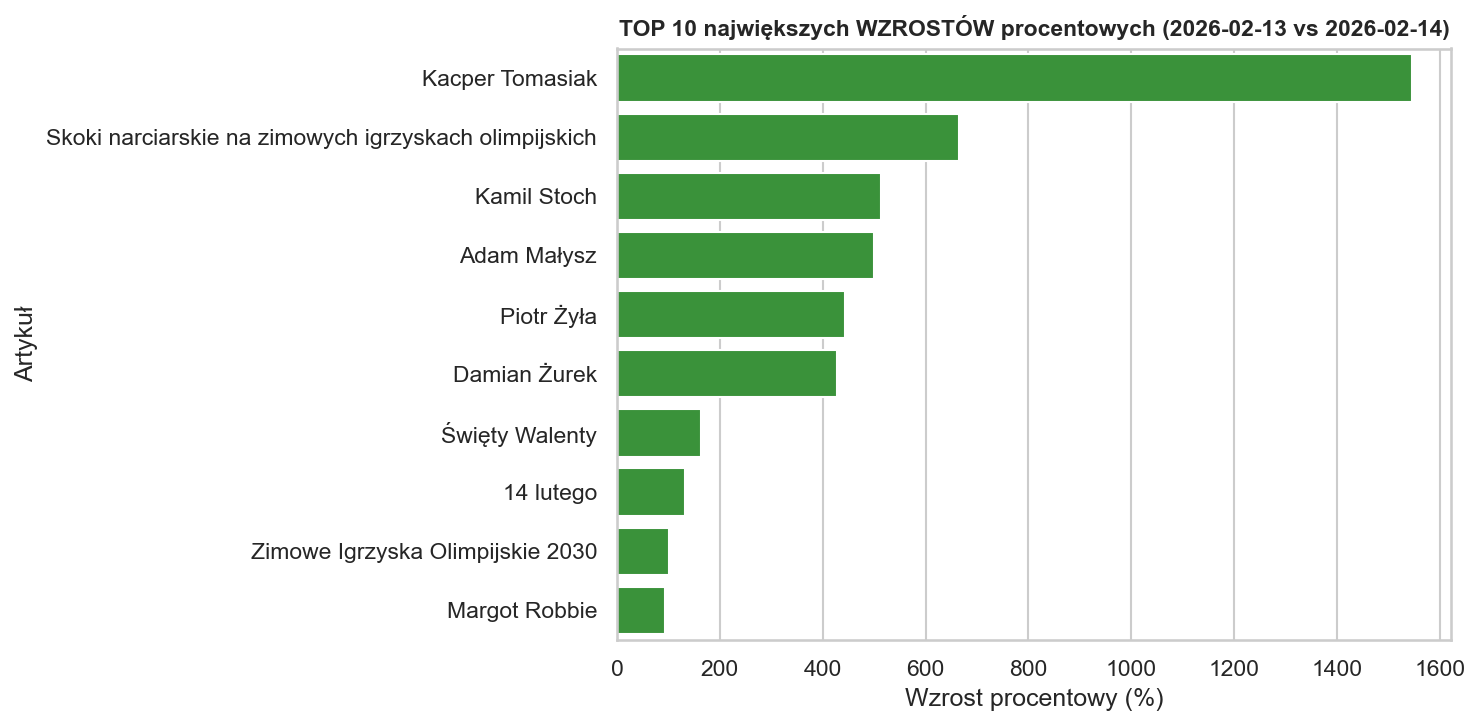

In [25]:
dates = sorted(df_pl["date"].unique())
if len(dates) >= 2:
    d1, d2 = dates[0], dates[1]
    p_wide = df_pl.pivot_table(index="article", columns="date", values="daily_total", fill_value=0)
    
    # Filtrujemy strony z minimalnym ruchem, żeby unikać sztucznych skoków z 1 na 5
    p_wide = p_wide[(p_wide[d1] >= 500) & (p_wide[d2] >= 500)]
    p_wide["pct_change"] = ((p_wide[d2] - p_wide[d1]) / p_wide[d1]) * 100
    
    # Największe wzrosty
    top_growth = p_wide.sort_values(by="pct_change", ascending=False).head(10).reset_index()
    top_growth["tytuł"] = top_growth["article"].str.replace("_", " ")

    plt.figure(figsize=(10, 5))
    sns.barplot(data=top_growth, x="pct_change", y="tytuł", color="#2ca02c")
    plt.title(f"TOP 10 największych WZROSTÓW procentowych ({d1} vs {d2})", fontsize=11, fontweight="bold")
    plt.xlabel("Wzrost procentowy (%)")
    plt.ylabel("Artykuł")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "chart_5a_relative_pct_growth.png")
    plt.show()

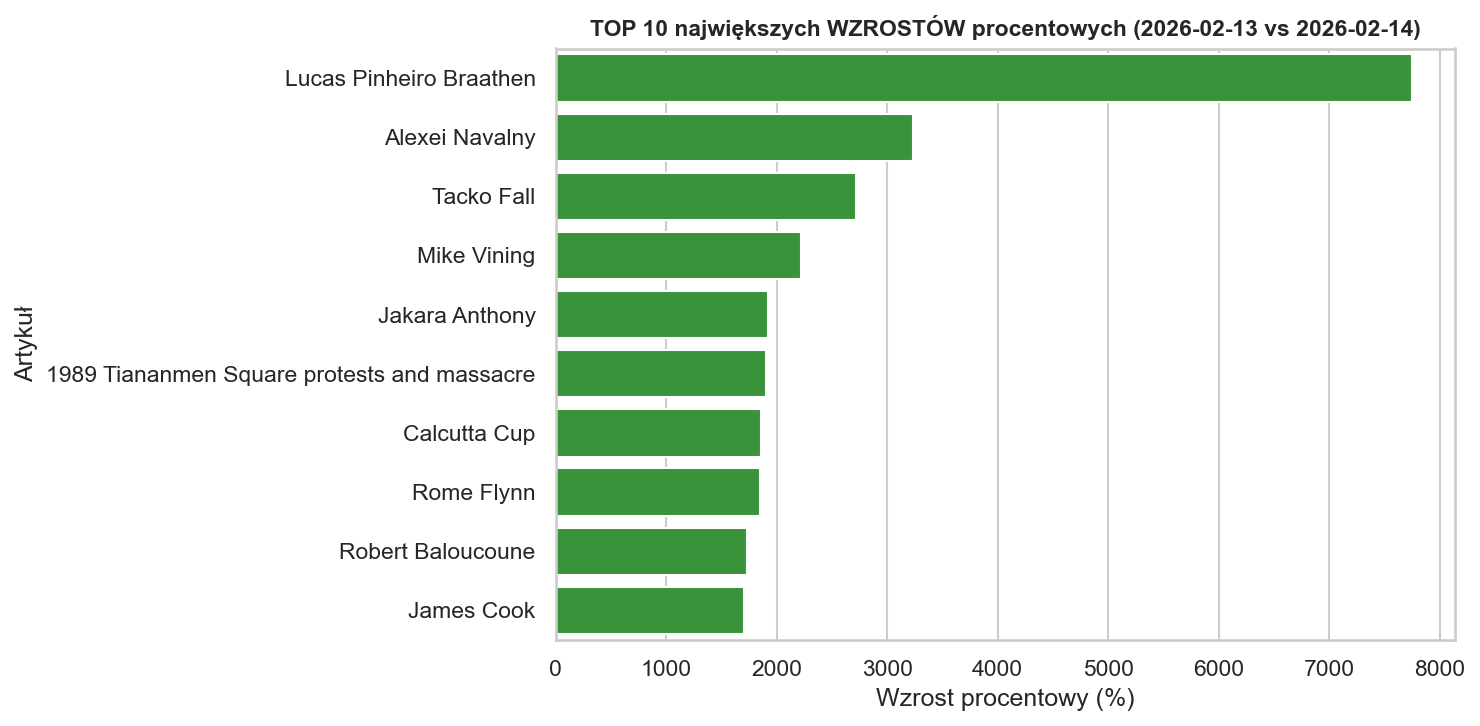

In [29]:
dates = sorted(df_pl["date"].unique())
if len(dates) >= 2:
    d1, d2 = dates[0], dates[1]
    p_wide = df_en.pivot_table(index="article", columns="date", values="daily_total", fill_value=0)
    
    # Filtrujemy strony z minimalnym ruchem, żeby unikać sztucznych skoków z 1 na 5
    p_wide = p_wide[(p_wide[d1] >= 500) & (p_wide[d2] >= 500)]
    p_wide["pct_change"] = ((p_wide[d2] - p_wide[d1]) / p_wide[d1]) * 100
    
    # Największe wzrosty
    top_growth = p_wide.sort_values(by="pct_change", ascending=False).head(10).reset_index()
    top_growth["tytuł"] = top_growth["article"].str.replace("_", " ")

    plt.figure(figsize=(10, 5))
    sns.barplot(data=top_growth, x="pct_change", y="tytuł", color="#2ca02c")
    plt.title(f"TOP 10 największych WZROSTÓW procentowych ({d1} vs {d2})", fontsize=11, fontweight="bold")
    plt.xlabel("Wzrost procentowy (%)")
    plt.ylabel("Artykuł")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "chart_5a_relative_pct_growth.png")
    plt.show()

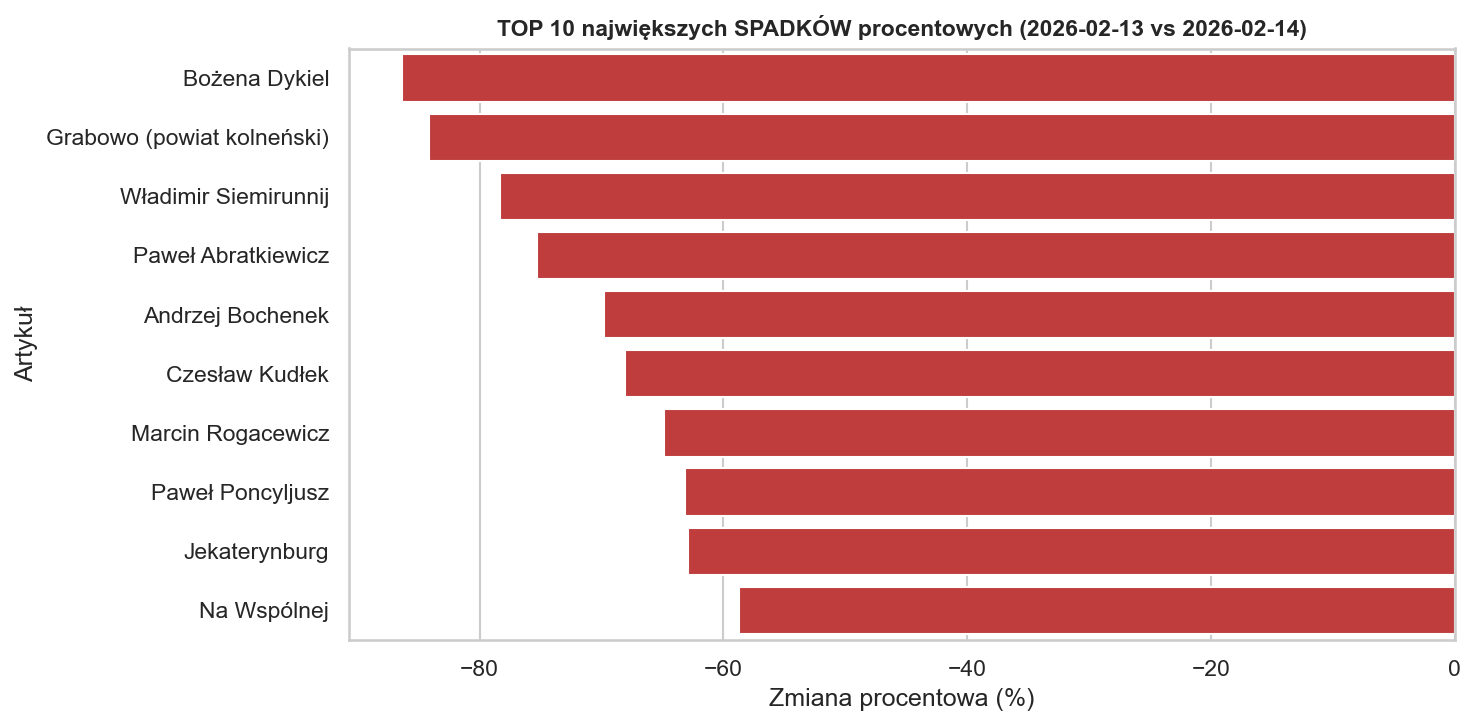

In [28]:
    top_drops = p_wide.sort_values(by="pct_change", ascending=True).head(10).reset_index()
    top_drops["tytuł"] = top_drops["article"].str.replace("_", " ")

    plt.figure(figsize=(10, 5))
    sns.barplot(data=top_drops, x="pct_change", y="tytuł", color="#d62728")
    plt.title(f"TOP 10 największych SPADKÓW procentowych ({d1} vs {d2})", fontsize=11, fontweight="bold")
    plt.xlabel("Zmiana procentowa (%)")
    plt.ylabel("Artykuł")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "chart_5b_relative_pct_drop.png")
    plt.show()

In [ ]:
    top_drops = p_wide.sort_values(by="pct_change", ascending=True).head(10).reset_index()
    top_drops["tytuł"] = top_drops["article"].str.replace("_", " ")

    plt.figure(figsize=(10, 5))
    sns.barplot(data=top_drops, x="pct_change", y="tytuł", color="#d62728")
    plt.title(f"TOP 10 największych SPADKÓW procentowych ({d1} vs {d2})", fontsize=11, fontweight="bold")
    plt.xlabel("Zmiana procentowa (%)")
    plt.ylabel("Artykuł")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "chart_5b_relative_pct_drop.png")
    plt.show()

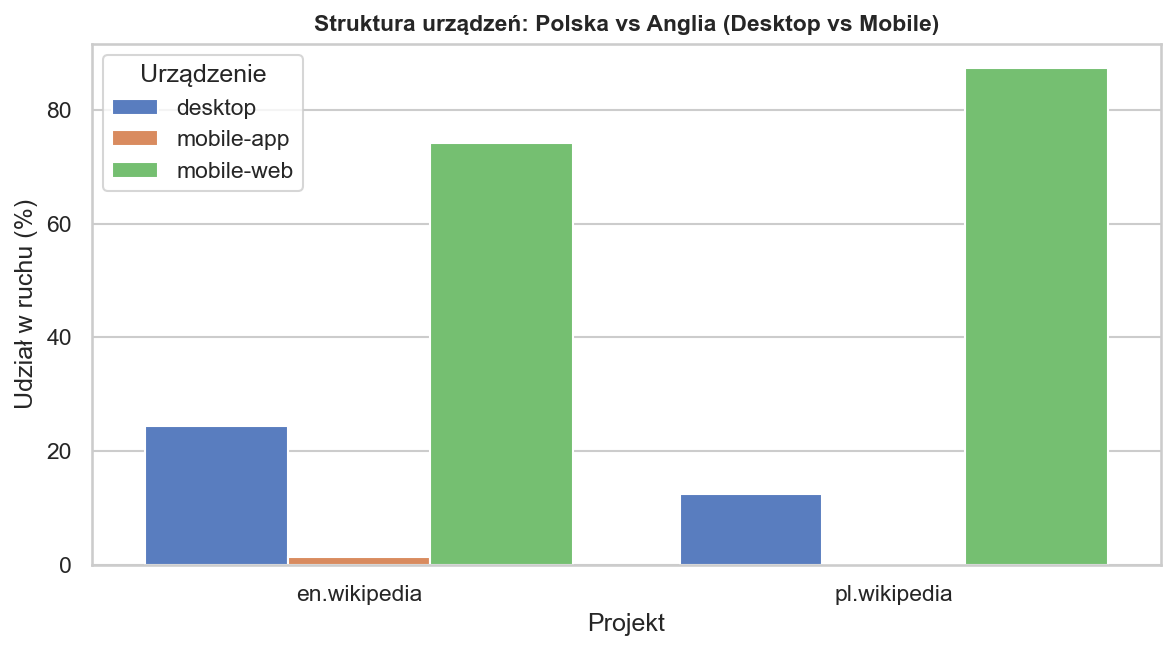

In [23]:
device_df = df_all.groupby(["project", "access"], as_index=False)["daily_total"].sum()
device_df["share"] = device_df.groupby("project")["daily_total"].transform(lambda x: 100 * x / x.sum())

plt.figure(figsize=(8, 4.5))
sns.barplot(data=device_df, x="project", y="share", hue="access")
plt.title("Struktura urządzeń: Polska vs Anglia (Desktop vs Mobile)", fontsize=11, fontweight="bold")
plt.xlabel("Projekt")
plt.ylabel("Udział w ruchu (%)")
plt.legend(title="Urządzenie")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "chart_6_device_share_comparison.png")
plt.show()